# BiLSTM + GloVe — Experiments and Learning Curves

**Team 4 — Workshop #2, Machine Learning 2026-III, Universidad Distrital Francisco José de Caldas.**

This notebook documents the recurrent sentiment model (**BiLSTM over pretrained GloVe embeddings**) and reproduces the figures used in the report: learning curves, per-class recall over epochs, the validation-vs-test gap, and the test confusion matrix.

Training itself lives in `src/bilstm/train.py` so every number here is reproducible from the command line:

```bash
poetry run python -m src.bilstm.model      # architecture + parameter counts (forward-pass check)
poetry run python -m src.bilstm.train      # two-phase training, writes checkpoints/bilstm_best.pt
poetry run python -m src.bilstm.evaluate   # test-set metrics, written to runs/eval_test_bilstm_best.json
```

This notebook only *reads* the artifacts those commands produced (`runs/bilstm-full/history.json` and `runs/eval_test_bilstm_best.json`); it does not retrain.

> **Run note.** The reported run was trained on CPU and stopped by hand after epoch 11, once the validation macro-F1 had clearly peaked (epoch 8) and begun to overfit. The best checkpoint is epoch 8, exactly what early stopping would have selected.

## 1. Architecture

```
Disneyland review
   -> word-level tokenisation (lowercase, keeps '!' and '?')
   -> vocabulary ids (18,219 words, built from TRAIN only)
   -> Embedding (200-d, initialised from GloVe 6B.200d, <pad>=0, <unk>=1)
   -> BiLSTM (2 layers, hidden 256, bidirectional)
   -> masked mean-pool  +  masked max-pool over time   (concatenated -> 1024-d)
   -> Dropout(0.5)
   -> Linear(1024 -> 3)
   -> logits (negative / neutral / positive)
```

**Why BiLSTM + GloVe.** Reviews are sequences, so a recurrent model is a natural fit, and it is a deliberately different architecture from the teammate's Transformer, letting the report compare an RNN against attention. Transfer learning enters through the embedding layer: GloVe already encodes word meaning learned from billions of tokens, so only the recurrent layers and the head are learned from scratch. Reading the review in both directions and pooling over all timesteps (mean = overall tone, max = strongest sentiment word) captures the verdict wherever it sits in the text.

**Transfer-learning note.** GloVe provides pretrained *embeddings*, not a pretrained BiLSTM. The recurrent network and classifier are trained for this task; the transfer is at the word-representation level.

In [1]:
from pathlib import Path
import json

import numpy as np
import matplotlib.pyplot as plt

# Resolve repo paths whether the notebook runs from notebooks/ or the repo root.
ROOT = Path.cwd()
if (ROOT / "notebooks").exists() and not (ROOT / "runs").exists():
    pass
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RUNS = ROOT / "runs"
FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

LABELS = ["negative", "neutral", "positive"]
WS1_BASELINE_MACRO_F1 = 0.6258  # Workshop #1 best (Logistic Regression, validation)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11})
print("repo root:", ROOT)

repo root: /home/mara-ar/Escritorio/UD/ML/JulianCelisCreator-ML-NLP-Sentimental-Analysis-W2


In [2]:
# Load the training history (per-epoch metrics) and the one-shot test evaluation.
history = json.loads((RUNS / "bilstm-full" / "history.json").read_text())
hist = history["history"]
test = json.loads((RUNS / "eval_test_bilstm_best.json").read_text())

epochs      = [r["epoch"]      for r in hist]
phase       = [r["phase"]      for r in hist]
train_loss  = [r["train_loss"] for r in hist]
val_loss    = [r["val_loss"]   for r in hist]
macro_f1    = [r["macro_f1"]   for r in hist]
accuracy    = [r["accuracy"]   for r in hist]
auc_roc     = [r["auc_roc"]    for r in hist]

best_epoch = history["best_epoch"]
finetune_start = next(r["epoch"] for r in hist if r["phase"] == "finetune")
print(f"epochs: {epochs[0]}..{epochs[-1]} | phase switch at epoch {finetune_start} | best epoch {best_epoch}")
print(f"best validation macro-F1: {history['best_val_macro_f1']:.4f}")
print(f"test macro-F1: {test['macro_f1']:.4f} | accuracy {test['accuracy']:.4f} | AUC-ROC {test['auc_roc']:.4f}")

epochs: 1..11 | phase switch at epoch 7 | best epoch 8
best validation macro-F1: 0.6414
test macro-F1: 0.6137 | accuracy 0.7706 | AUC-ROC 0.8791


## 2. Learning curves

The brief asks for loss and metric curves over training. The vertical dashed line marks the phase switch: left of it GloVe is frozen (only the BiLSTM + head learn), right of it GloVe is unfrozen and fine-tuned at a lower learning rate.

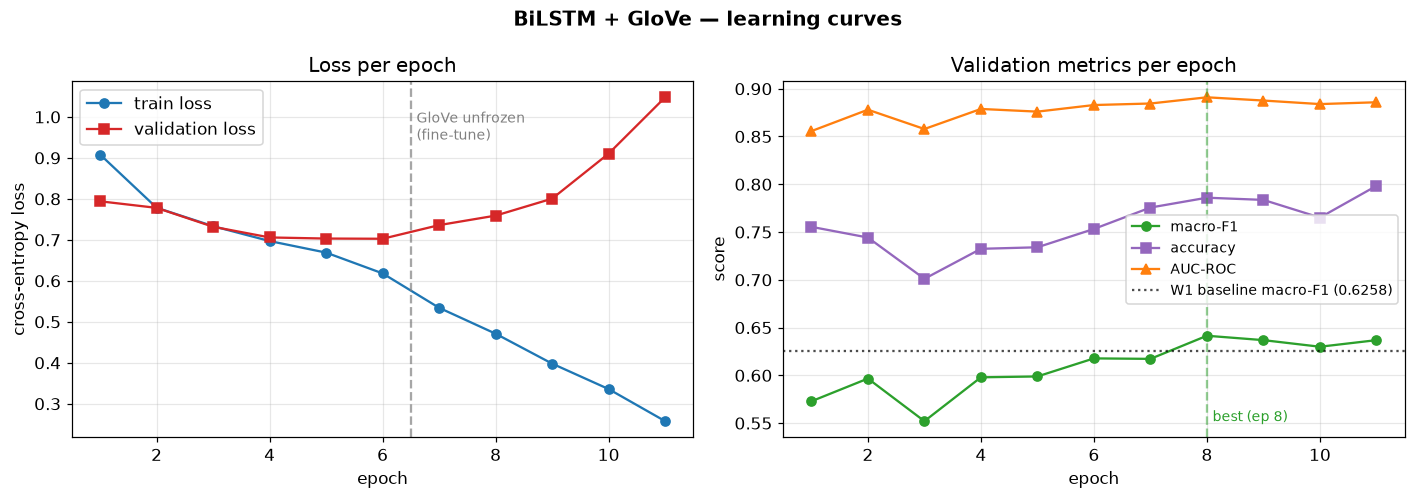

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))

# --- loss ---
ax1.plot(epochs, train_loss, "o-", label="train loss", color="#1f77b4")
ax1.plot(epochs, val_loss, "s-", label="validation loss", color="#d62728")
ax1.axvline(finetune_start - 0.5, ls="--", color="gray", alpha=0.7)
ax1.text(finetune_start - 0.4, max(val_loss) * 0.97, "GloVe unfrozen\n(fine-tune)",
         fontsize=9, color="gray", va="top")
ax1.set_xlabel("epoch"); ax1.set_ylabel("cross-entropy loss")
ax1.set_title("Loss per epoch"); ax1.legend()

# --- validation metrics ---
ax2.plot(epochs, macro_f1, "o-", label="macro-F1", color="#2ca02c")
ax2.plot(epochs, accuracy, "s-", label="accuracy", color="#9467bd")
ax2.plot(epochs, auc_roc, "^-", label="AUC-ROC", color="#ff7f0e")
ax2.axhline(WS1_BASELINE_MACRO_F1, ls=":", color="black", alpha=0.7,
            label=f"W1 baseline macro-F1 ({WS1_BASELINE_MACRO_F1})")
ax2.axvline(best_epoch, ls="--", color="#2ca02c", alpha=0.5)
ax2.text(best_epoch + 0.1, min(macro_f1), f"best (ep {best_epoch})",
         fontsize=9, color="#2ca02c")
ax2.set_xlabel("epoch"); ax2.set_ylabel("score")
ax2.set_title("Validation metrics per epoch"); ax2.legend(fontsize=9)

fig.suptitle("BiLSTM + GloVe — learning curves", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "learning_curves.png", bbox_inches="tight")
plt.show()

**Reading the curves.** In the frozen phase both losses fall together and macro-F1 climbs to ~0.62. Once GloVe is unfrozen, train loss keeps dropping but validation loss turns upward — the classic overfitting signature. Validation macro-F1 peaks at epoch 8 and does not recover, which is exactly why the saved checkpoint is epoch 8 and not the last epoch. This is the same behaviour the Transformer showed; the defence against it (dropout 0.5, weight decay, and selecting the best-validation checkpoint) is built into the training loop.

## 3. Per-class recall over epochs

Macro-F1 hides which class drives the score. The `neutral` class is the hard one in this corpus (it was for the baselines too), so it is worth watching separately.

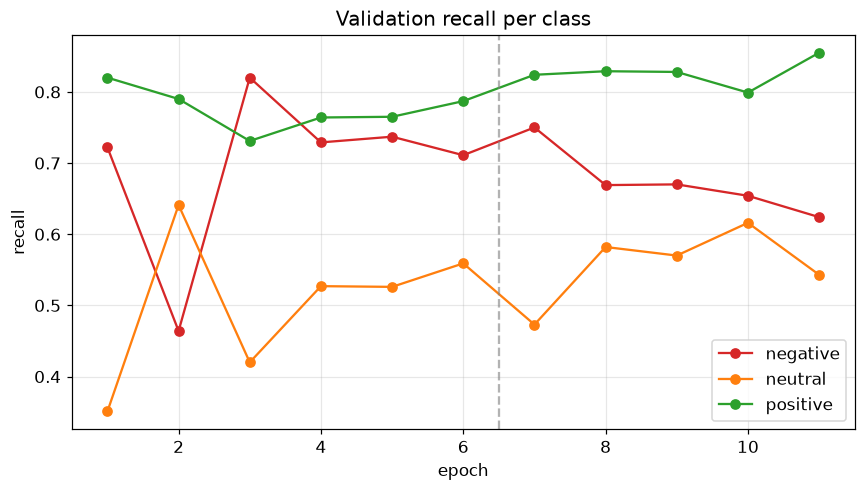

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.6))
colors = {"negative": "#d62728", "neutral": "#ff7f0e", "positive": "#2ca02c"}
for label in LABELS:
    series = [r["recall"][label] for r in hist]
    ax.plot(epochs, series, "o-", label=f"{label}", color=colors[label])
ax.axvline(finetune_start - 0.5, ls="--", color="gray", alpha=0.6)
ax.set_xlabel("epoch"); ax.set_ylabel("recall")
ax.set_title("Validation recall per class")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "recall_per_class.png", bbox_inches="tight")
plt.show()

**Reading per-class recall.** `positive` is learned almost immediately (it is the majority class). `negative` and `neutral` trade off against each other as training progresses — balanced class weights in the loss keep the model from collapsing onto the majority class, which is why `neutral` recall stays well above zero instead of being ignored.

## 4. Test confusion matrix

Scored once, on the held-out test split, from the epoch-8 checkpoint.

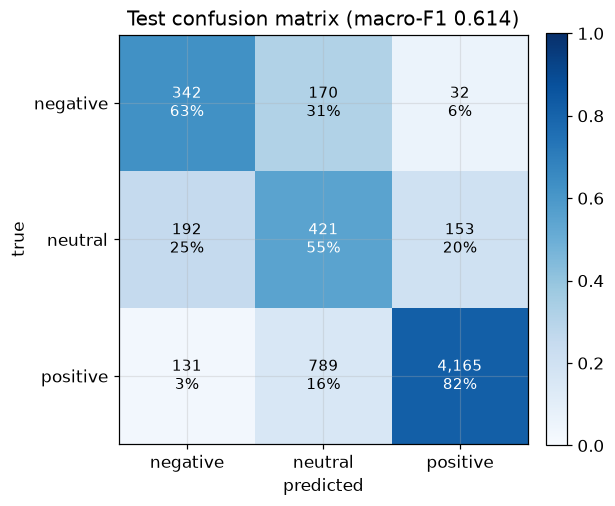

In [5]:
cm = np.array(test["confusion"])
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(5.6, 5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_yticks(range(3))
ax.set_xticklabels(LABELS); ax.set_yticklabels(LABELS)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(f"Test confusion matrix (macro-F1 {test['macro_f1']:.3f})")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:,}\n{cm_norm[i, j]:.0%}", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=10)
fig.colorbar(im, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(FIG / "confusion_matrix_test.png", bbox_inches="tight")
plt.show()

**Reading the matrix.** `positive` is recovered well (82%). The dominant error is `neutral` reviews predicted as `positive` (789 of them): mildly worded reviews with any positive phrasing drift into the majority class. This is the single biggest contributor to the lower macro-F1 and the clearest target for future work.

## 5. Comparison against Workshop 1 baselines and the Transformer

All numbers are on the **same test split** (6,395 reviews), the same metrics as Workshop 1.

In [6]:
# Baseline / Transformer numbers taken from the repository README (same test split).
rows = [
    ("RoBERTa-base (W2, teammate)",       0.8460, 0.9357, 0.7130),
    ("BERT-base-uncased (W2, alt.)",      0.8394, 0.9265, 0.6973),
    ("BiLSTM + GloVe (W2, this model)",   test["accuracy"], test["auc_roc"], test["macro_f1"]),
    ("Logistic Regression (W1)",          0.7787, 0.8879, 0.6169),
    ("Multinomial Naive Bayes (W1)",      0.8013, 0.8286, 0.4299),
    ("Random Forest (W1)",                0.7962, 0.8621, 0.3037),
    ("Majority class (W1)",               0.7952, 0.5000, 0.2953),
]
print(f"{'model':<34}{'acc':>8}{'AUC':>8}{'macroF1':>10}")
print("-" * 60)
for name, acc, auc, f1 in rows:
    print(f"{name:<34}{acc:>8.4f}{auc:>8.4f}{f1:>10.4f}")

model                                  acc     AUC   macroF1
------------------------------------------------------------
RoBERTa-base (W2, teammate)         0.8460  0.9357    0.7130
BERT-base-uncased (W2, alt.)        0.8394  0.9265    0.6973
BiLSTM + GloVe (W2, this model)     0.7706  0.8791    0.6137
Logistic Regression (W1)            0.7787  0.8879    0.6169
Multinomial Naive Bayes (W1)        0.8013  0.8286    0.4299
Random Forest (W1)                  0.7962  0.8621    0.3037
Majority class (W1)                 0.7952  0.5000    0.2953


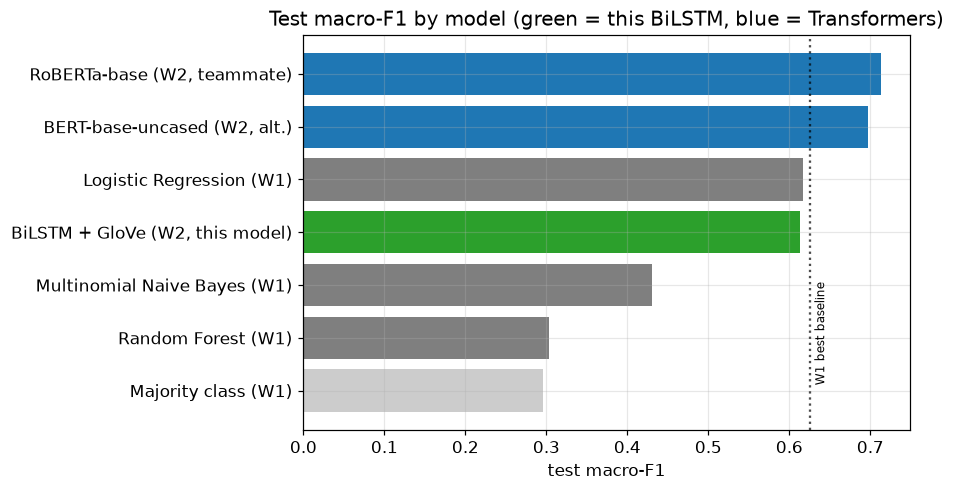

In [7]:
names   = [r[0] for r in rows]
f1s     = [r[3] for r in rows]
colors_bar = ["#1f77b4", "#1f77b4", "#2ca02c", "#7f7f7f", "#7f7f7f", "#7f7f7f", "#cccccc"]

order = np.argsort(f1s)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.barh([names[i] for i in order], [f1s[i] for i in order],
        color=[colors_bar[i] for i in order])
ax.axvline(WS1_BASELINE_MACRO_F1, ls=":", color="black", alpha=0.7)
ax.text(WS1_BASELINE_MACRO_F1 + 0.005, 0.1, "W1 best baseline", rotation=90,
        fontsize=8, va="bottom")
ax.set_xlabel("test macro-F1")
ax.set_title("Test macro-F1 by model (green = this BiLSTM, blue = Transformers)")
fig.tight_layout()
fig.savefig(FIG / "model_comparison_macro_f1.png", bbox_inches="tight")
plt.show()

## 6. Conclusions

- **The BiLSTM + GloVe reaches test macro-F1 0.614**, essentially matching the best Workshop 1 baseline (Logistic Regression, 0.617) and far above Naive Bayes, Random Forest and the majority-class floor on the macro metric.
- **It does not reach the Transformers** (RoBERTa 0.713, BERT 0.697). The gap is expected: self-attention models richer long-range context than a recurrent encoder over static word vectors, and they fine-tune far more pretrained parameters.
- **The limiting factor is the `neutral` class** — the confusion matrix shows neutral reviews leaking into `positive`. This is the shared weak spot of every model on this corpus and the obvious direction for improvement.
- **Overfitting was handled, not avoided.** Both this model and the Transformer overfit in the fine-tuning phase; both were saved at their best-validation epoch, so the delivered checkpoint generalises (val 0.641 -> test 0.614, a small and healthy gap).

The architecture choice is validated: a recurrent model with transferred embeddings is a sound, honest alternative to a Transformer for this task — competitive with classical baselines, below attention, and clear about why.